# Часть 1. Проверка гипотезы в Python и составление аналитической записки

Вы предобработали данные в SQL, и теперь они готовы для проверки гипотезы в Python. Загрузите данные пользователей из Москвы и Санкт-Петербурга c суммой часов их активности из файла yandex_knigi_data.csv. Если работаете локально, скачать файл можно по ссылке.

Проверьте наличие дубликатов в идентификаторах пользователей. Сравните размеры групп, их статистики и распределение.

Напомним, как выглядит гипотеза: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

Нулевая гипотеза $H_0: \mu_{\text{СПб}} \leq \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.

Альтернативная гипотеза $H_1: \mu_{\text{СПб}} > \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

По результатам анализа данных подготовьте аналитическую записку, в которой опишите:

Выбранный тип t-теста и уровень статистической значимости.

Результат теста, или p-value.

Вывод на основе полученного p-value, то есть интерпретацию результатов.

Одну или две возможные причины, объясняющие полученные результаты.

## Напишите заголовок первой части проекта здесь

- Автор: Дегтярёва Александра
- Дата: 14.02.2026

## Цели и задачи проекта

**Цель:**
Проверка гипотезы 

**Задачи:**
- проверить наличие дубликатов 
- сравнить замеры групп и их статистики
- проверить гипотезу 
- описать результаты 

## Описание данных

Датафрейм содержит 8784 строки и 3 столбца:

`city` - содержит информацию о городе (Москва или Санкт-Петербург)

`puid` - идентификатор пользователя

`hours` - общее количество часов активности 

## Содержимое проекта

- Загрузка и знакомство с данными
- Поиск пропущенных значений
- Работа с дубликатами и подготовка данных к А/В тесту 
- Анализ результатов

## 1. Загрузка данных и знакомство с ними

Загрузите данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла `/datasets/yandex_knigi_data.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from scipy.stats import ttest_ind
import scipy.stats as stats

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

from math import ceil

from statsmodels.stats.proportion import proportions_ztest

In [2]:
df = pd.read_csv('/datasets/yandex_knigi_data.csv')
df = df.drop('Unnamed: 0', axis=1) # удаляю столбец со старыми индексами

In [3]:
df.head()

,city,puid,hours
0,Москва,9668,26.167776
1,Москва,16598,82.111217
2,Москва,80401,4.656906
3,Москва,140205,1.840556
4,Москва,248755,151.326434


In [4]:
df.tail()

,city,puid,hours
8779,Санкт-Петербург,1130000028554332,4.107774
8780,Санкт-Петербург,1130000030307246,45.069222
8781,Санкт-Петербург,1130000038726322,0.211944
8782,Санкт-Петербург,1130000047892100,4.311841
8783,Санкт-Петербург,1130000061443598,20.847222


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   city    8784 non-null   object 
 1   puid    8784 non-null   int64  
 2   hours   8784 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 206.0+ KB


In [6]:
df.duplicated().sum()

0

In [7]:
group_a = df[df['city'] == 'Москва']['puid']
group_b = df[df['city'] == 'Санкт-Петербург']['puid']

duplicate_puid  = list(set(group_a) & set(group_b))
print(duplicate_puid)

[439054848, 98068993, 84978689, 331188228, 59679749, 790564870, 40698887, 162106378, 1078819852, 1684058125, 1130000018954257, 959563282, 571554323, 1358054932, 313990163, 1778617878, 1210363415, 1316543509, 649885721, 1183963675, 1395494429, 1314529823, 1145886241, 1593760291, 1725564965, 24138278, 520518182, 363351088, 108083761, 570189363, 584447544, 860187201, 309104707, 550835780, 441112643, 1977784899, 1406501962, 528250442, 103543372, 1616171597, 589188176, 989693522, 1958805587, 401065555, 1557916755, 429727314, 1130000028554332, 488154206, 1965288031, 10597984, 9979490, 301108324, 1607495785, 767485035, 453988975, 912829040, 955554416, 1672056947, 819309176, 10815097, 196683896, 1076879993, 1974615673, 531369086, 1011254911, 555866239, 258809476, 66998918, 360290950, 1085783174, 236601993, 359740041, 998045836, 888840333, 2019864206, 1109631631, 1713008273, 317826707, 1236880533, 46837910, 1166679702, 137198745, 1891219106, 987817124, 1735154341, 176447657, 1748029097, 3793466

In [8]:
df_clean = df[~df['puid'].isin(duplicate_puid)]

In [9]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8296 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   city    8296 non-null   object 
 1   puid    8296 non-null   int64  
 2   hours   8296 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 259.2+ KB


In [10]:
group_msk = df_clean[df_clean['city'] == 'Москва']
msk_count = group_msk['puid'].nunique()

group_spb = df_clean[df_clean['city'] == 'Санкт-Петербург']
spb_count = group_spb['puid'].nunique()
print(msk_count,spb_count)

5990 2306


In [11]:
print("Москва:")
print(group_msk['hours'].describe())

print("\nСанкт-Петербург:")
print(group_spb['hours'].describe())

std_msk = np.std(group_msk['hours'], ddof=1)
std_spb = np.std(group_spb['hours'], ddof=1)

Москва:
count    5990.000000
mean       10.848192
std        36.925622
min         0.000022
25%         0.057042
50%         0.888232
75%         5.933439
max       857.209373
Name: hours, dtype: float64

Санкт-Петербург:
count    2306.000000
mean       11.264433
std        39.831755
min         0.000025
25%         0.060173
50%         0.875355
75%         6.138424
max       978.764775
Name: hours, dtype: float64


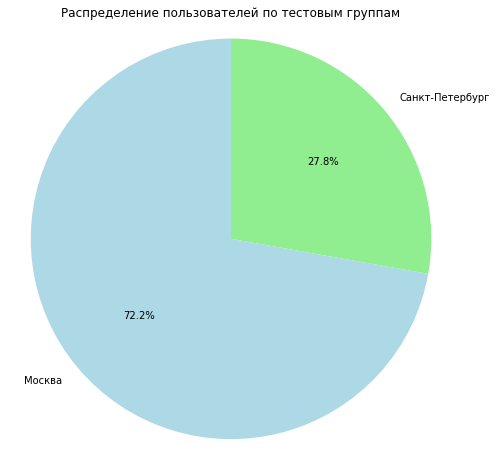

In [12]:
labels = ['Москва', 'Санкт-Петербург']
sizes = [msk_count, spb_count]
colors = ['lightblue', 'lightgreen']

plt.figure(figsize=(8, 8))
plt.pie(sizes, 
        labels=labels, 
        colors=colors, 
        autopct='%1.1f%%', 
        startangle=90)

plt.title('Распределение пользователей по тестовым группам')
plt.axis('equal')

plt.show()

Видим что количество пользователей в Москве явно превышает кол-во в Санкт-Петербурге

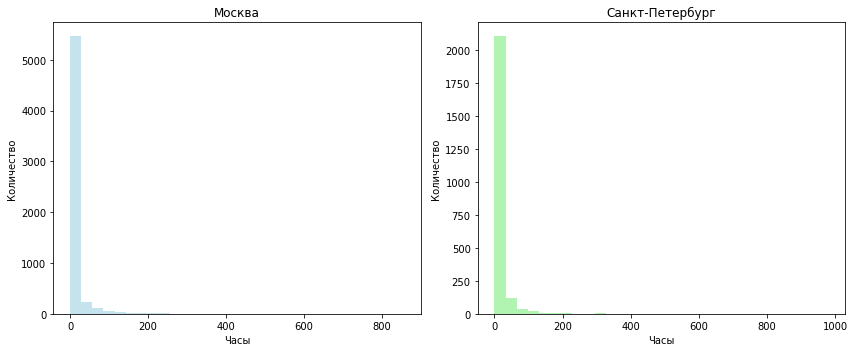

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.hist(group_msk['hours'],
         bins=30, 
         alpha=0.7,
         color='lightblue')

ax1.set_title('Москва')
ax1.set_xlabel('Часы')
ax1.set_ylabel('Количество')


ax2.hist(group_spb['hours'],
         bins=30,
         alpha=0.7,
         color='lightgreen')

ax2.set_title('Санкт-Петербург')
ax2.set_xlabel('Часы')
ax2.set_ylabel('Количество')

plt.tight_layout()
plt.show()

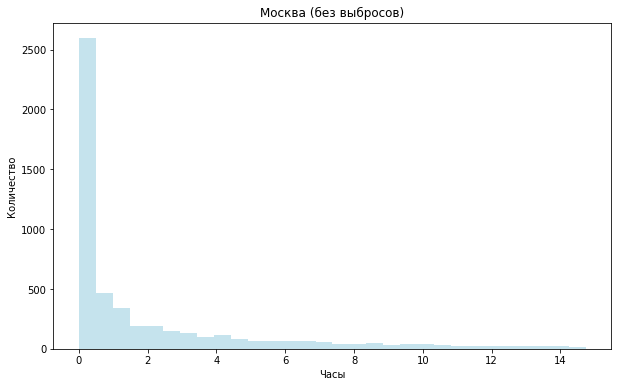

In [14]:
# смотрим данные без выбросов
def remove_outliers(data):
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return data[(data >= lower_bound) & (data <= upper_bound)]


plt.figure(figsize=(10, 6))

msk_no_outliers = remove_outliers(group_msk['hours'])

plt.hist(msk_no_outliers, 
         bins=30, 
         alpha=0.7, 
         color='lightblue' )

plt.title('Москва (без выбросов)')
plt.xlabel('Часы')
plt.ylabel('Количество')

plt.show()


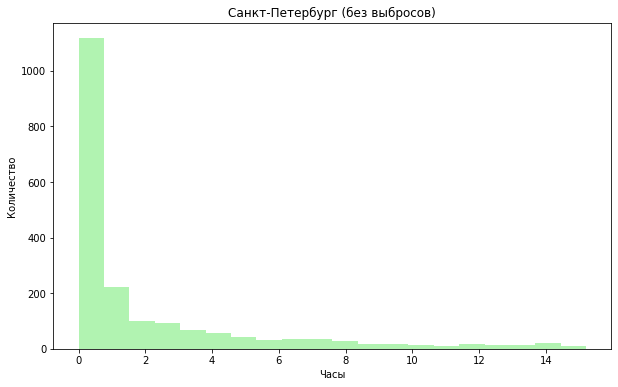

In [15]:
plt.figure(figsize=(10, 6))

spb_no_outliers = remove_outliers(group_spb['hours'])

plt.hist(spb_no_outliers, 
         bins=20,
         alpha=0.7, 
         color='lightgreen')

plt.title('Санкт-Петербург (без выбросов)')
plt.xlabel('Часы')
plt.ylabel('Количество')

plt.show()

## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

In [16]:
msk_hours = df_clean[df_clean['city'] == 'Москва']['hours']
spb_hours = df_clean[df_clean['city'] == 'Санкт-Петербург']['hours']

# t-test Уэлча (две независимые выборки, односторонний тест)
t_stat, p_value = stats.ttest_ind(
    spb_hours,
    msk_hours,
    equal_var=False,
    alternative='greater'
)

print(f"t-stat = {t_stat:.4f}")
print(f"p-value = {p_value:.4f}")

alpha = 0.05

if p_value < alpha:
    print("H0 отвергается: пользователи из СПб проводят статистически значимо больше времени в приложении, чем пользователи из Москвы.")
else:
    print("H0 не отвергается: нет статистически значимых оснований утверждать, что пользователи из СПб проводят больше времени, чем пользователи из Москвы.")


t-stat = 0.4350
p-value = 0.3318
H0 не отвергается: нет статистически значимых оснований утверждать, что пользователи из СПб проводят больше времени, чем пользователи из Москвы.


## 3. Аналитическая записка
По результатам анализа данных подготовьте аналитическую записку, в которой опишете:

- Выбранный тип t-теста и уровень статистической значимости.

- Результат теста, или p-value.

- Вывод на основе полученного p-value, то есть интерпретацию результатов.

- Одну или две возможные причины, объясняющие полученные результаты.



* Тест: t-тест Уэлча (две независимые выборки), **односторонний**
* Уровень значимости: α = 0.05
* **Результат:** p-value = **0.3318**
* **Вывод:** p-value > 0.05 → **H0 не отвергается**. Нет статистически значимых доказательств, что пользователи из СПб проводят больше времени, чем пользователи из Москвы.

Возможные причины:

  1. Разница между городами реально отсутствует/очень мала.
  2. Большой разброс активности пользователей мешает выявить отличие.


----

# Часть 2. Анализ результатов A/B-тестирования

Теперь вам нужно проанализировать другие данные. Представьте, что к вам обратились представители интернет-магазина BitMotion Kit, в котором продаются геймифицированные товары для тех, кто ведёт здоровый образ жизни. У него есть своя целевая аудитория, даже появились хиты продаж: эспандер со счётчиком и напоминанием, так и подстольный велотренажёр с Bluetooth.

В будущем компания хочет расширить ассортимент товаров. Но перед этим нужно решить одну проблему. Интерфейс онлайн-магазина слишком сложен для пользователей — об этом говорят отзывы.

Чтобы привлечь новых клиентов и увеличить число продаж, владельцы магазина разработали новую версию сайта и протестировали его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку.

Ваша задача — провести оценку результатов A/B-теста. В вашем распоряжении:

* данные о действиях пользователей и распределении их на группы,

* техническое задание.

Оцените корректность проведения теста и проанализируйте его результаты.

## 1. Опишите цели исследования.



- Проверить корректно ли проведён A/B-тест
- Оценить влияет ли новая версия сайта на конверсию в покупку
- Сделать вывод: можно ли внедрять новую версию сайта


## 2. Загрузите данные, оцените их целостность.


In [17]:
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [18]:
participants.head()

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


In [19]:
participants.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB


Данные не содержат пропусков

In [20]:
events.head()

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


In [21]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  object        
 1   event_dt    787286 non-null  datetime64[ns]
 2   event_name  787286 non-null  object        
 3   details     249022 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 24.0+ MB


Данные содержат большой процент пропусков в столбце `details`

## 3. По таблице `ab_test_participants` оцените корректность проведения теста:

   3\.1 Выделите пользователей, участвующих в тесте, и проверьте:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [22]:
# колонка с комбинацией теста и группы
participants['ab_test_group'] = participants['ab_test'] + '_' + participants['group']

user_test_groups = participants.groupby('user_id')['ab_test_group'].nunique().reset_index()
user_test_groups.columns = ['user_id', 'num_groups']

valid_users = user_test_groups[user_test_groups['num_groups'] == 1]['user_id']

filtered_participants = participants[participants['user_id'].isin(valid_users)]

filtered_participants = filtered_participants[filtered_participants['ab_test'] == 'interface_eu_test']

total_users = filtered_participants['user_id'].nunique()
group_a = filtered_participants[filtered_participants['group'] == 'A']['user_id'].nunique()
group_b = filtered_participants[filtered_participants['group'] == 'B']['user_id'].nunique()

print(f"Всего пользователей после фильтрации: {total_users}")
print(f"Группа A: {group_a}")
print(f"Группа B: {group_b}")

Всего пользователей после фильтрации: 9963
Группа A: 4952
Группа B: 5011


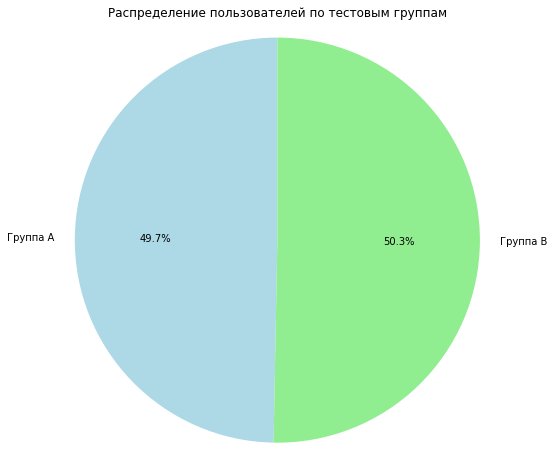

In [23]:
labels = ['Группа А', 'Группа В']
sizes = [group_a, group_b]
colors = ['lightblue', 'lightgreen']

plt.figure(figsize=(8, 8))
plt.pie(sizes, 
        labels=labels, 
        colors=colors, 
        autopct='%1.1f%%', 
        startangle=90)

plt.title('Распределение пользователей по тестовым группам')
plt.axis('equal')

plt.show()

3\.2 Проанализируйте данные о пользовательской активности по таблице `ab_test_events`:

- оставьте только события, связанные с участвующими в изучаемом тесте пользователями;

In [24]:
participants_users = filtered_participants['user_id'].unique()

events_filtered = events[events['user_id'].isin(participants_users)]

- определите горизонт анализа: рассчитайте время (лайфтайм) совершения события пользователем после регистрации и оставьте только те события, которые были выполнены в течение первых семи дней с момента регистрации;

In [25]:
# минимальная дату события для каждого пользователя 
user_first_event = events_filtered.groupby('user_id')['event_dt'].min().reset_index()
user_first_event.columns = ['user_id', 'first_event_time']

# присоединяем время первого события к событиям
events_with_first = events_filtered.merge(user_first_event, on='user_id', how='inner')

events_with_first['event_dt'] = pd.to_datetime(events_with_first['event_dt'])
events_with_first['first_event_time'] = pd.to_datetime(events_with_first['first_event_time'])

# разница 
events_with_first['lifetime'] = events_with_first['event_dt'] - events_with_first['first_event_time']

# фильтр
seven_days = pd.Timedelta(days=7)
events_7days = events_with_first[events_with_first['lifetime'] <= seven_days]

print(f"Событий в первые 7 дней: {len(events_7days)}")

Событий в первые 7 дней: 63805


Оцените достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:

- базовый показатель конверсии — 30%,

- мощность теста — 80%,

- достоверность теста — 95%.

In [26]:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 0.8  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = 0.03  # Минимальный детектируемый эффект (абсолют)
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")
print(f"Общий размер выборки: {int(sample_size)*2}")

Необходимый размер выборки для каждой группы: 3761
Общий размер выборки: 7522


Размер выборки соответсвует нашим данным 

- рассчитайте для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

In [27]:
total_a = filtered_participants[filtered_participants['group'] == 'A']['user_id'].nunique()
total_b = filtered_participants[filtered_participants['group'] == 'B']['user_id'].nunique()

purchases = events_7days[events_7days['event_name'] == 'purchase']['user_id'].unique()

purchases_a = filtered_participants[(filtered_participants['group'] == 'A') & 
                                 (filtered_participants['user_id'].isin(purchases))]['user_id'].nunique()

purchases_b = filtered_participants[(filtered_participants['group'] == 'B') & 
                                 (filtered_participants['user_id'].isin(purchases))]['user_id'].nunique()

conversion_a = purchases_a / total_a 
conversion_b = purchases_b / total_b 

print(f"Группа A:")
print(f"Всего посетителей: {total_a}")
print(f"Совершили покупку: {purchases_a}")
print(f"Конверсия: {conversion_a:.2%}")

print(f"Группа B:")
print(f"Всего посетителей: {total_b}")
print(f"Совершили покупку: {purchases_b}")
print(f"Конверсия: {conversion_b:.2%}")
print(f"Разница в конверсии: {conversion_b - conversion_a:+.2%}")

Группа A:
Всего посетителей: 4952
Совершили покупку: 1377
Конверсия: 27.81%
Группа B:
Всего посетителей: 5011
Совершили покупку: 1480
Конверсия: 29.54%
Разница в конверсии: +1.73%


- сделайте предварительный общий вывод об изменении пользовательской активности в тестовой группе по сравнению с контрольной.

На основе проведённых расчетов наблюдается `рост конверсии на ~ 1.8%`, что говорит о `положительном` влиянии изменений. Но по ТЗ требовалось минимум 3% поэтому нужно подтвердить выводы статистическим тестом 

## 4. Проведите оценку результатов A/B-тестирования:

- Проверьте изменение конверсии подходящим статистическим тестом, учитывая все этапы проверки гипотез.

In [28]:
from statsmodels.stats.proportion import proportions_ztest

n_a, n_b = total_a, total_b  # размеры выборок
m_a, m_b = purchases_a, purchases_b  # количество успехов

p_a, p_b = m_a/n_a, m_b/n_b

# Проверка предпосылок
if (p_a*n_a > 10) and ((1-p_a)*n_a > 10) and (p_b*n_b > 10) and ((1-p_b)*n_b > 10):
    print('Предпосылка о достаточном количестве данных выполняется')
else:
    print('Предпосылка о достаточном количестве данных НЕ выполняется')

alpha = 0.05

# Тест: проверяем что p_A < p_B 
stat_ztest, p_value_ztest = proportions_ztest(
    [m_a, m_b],
    [n_a, n_b],
    alternative='smaller'  # H1: p_A < p_B
)
print(p_value_ztest)
if p_value_ztest > alpha:
    print(f'\np-value > {alpha}')
    print('Не можем отклонить нулевую гипотезу')
    print('Нет доказательств, что конверсия в группе B выше')
else:
    print(f'\np-value < {alpha}')
    print('Отклоняем нулевую гипотезу')
    print('Статистически доказано, что конверсия в группе B выше')

Предпосылка о достаточном количестве данных выполняется
0.028262547212292124

p-value < 0.05
Отклоняем нулевую гипотезу
Статистически доказано, что конверсия в группе B выше


- Опишите выводы по проведённой оценке результатов A/B-тестирования. Что можно сказать про результаты A/B-тестирования? Был ли достигнут ожидаемый эффект в изменении конверсии?

Новая версия сайта положительно влияет что подтверждает статистическая проверка. Конверсия выросла с 28.54% (группа A) до 30.09% (группа B).

`Эффект: +1.8`

`Целевой эффект (+3%) не достигнут`, однако `положительное влияние на конверсию подтверждено`. Новый дизайн работает лучше текущей версии.